In [1]:
# plot accuracy metrics from DDS training and validation (temporal)
import sys, os, glob, pickle, toml, json
import pickle
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.cm as cm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import xarray as xr

def set_background(ax):
    ax.set_extent([-121, -72, 25, 50])

    # Background boundaries
    # ax.add_feature(cfeature.LAND)
    ax.add_feature(cfeature.COASTLINE)
    ax.add_feature(cfeature.BORDERS)
    states_provinces = cfeature.NaturalEarthFeature(
        category='cultural',
        name='admin_1_states_provinces_lines',
        scale='50m',
        facecolor='none')
    ax.add_feature(states_provinces, edgecolor='gray')
    
    return ax


In [15]:
tarexp = 'exp9'
iterall = 16
outpath_parent = f"/glade/campaign/cgd/tss/people/guoqiang/HBV_CAMELS/LSE{tarexp}"

# subsetPath = f'/glade/campaign/cgd/tss/people/guoqiang/HBV_CAMELS/data_Yalan/Sub531ID.txt'
subsetPath = f'/glade/campaign/cgd/tss/people/guoqiang/HBV_CAMELS/data_Yalan/subsetID/Sub100ID.txt'
with open(subsetPath, 'r') as fp:
     camels_ids = json.load(fp)

In [8]:
# load all iterations

df_train_alliter = []
df_test_alliter = []

for iter in range(0, iterall+1):

    df_train_metric = []
    df_test_metric = []
    for tarbasin in range(len(camels_ids)):
        idi = camels_ids[tarbasin]
        infile_i = f'{outpath_parent}/{idi}/optmz_simu/bestparam_train_eval_iter{iter}.csv'
        dfi = pd.read_csv(infile_i)
        dfi['hruID'] = idi
        dfi['iter'] = iter
        df_train_metric.append(dfi)
    
        infile_i = f'{outpath_parent}/{idi}/optmz_simu/bestparam_test_eval_iter{iter}.csv'
        dfi = pd.read_csv(infile_i)
        dfi['hruID'] = idi
        dfi['iter'] = iter
        df_test_metric.append(dfi)
    
    df_train_metric = pd.concat(df_train_metric)
    df_test_metric = pd.concat(df_test_metric)

    df_train_alliter.append(df_train_metric)
    df_test_alliter.append(df_test_metric)

df_train_alliter = pd.concat(df_train_alliter)
df_test_alliter = pd.concat(df_test_alliter)


# progress of iterative calibration and test


In [9]:

metrics = ['nse', 'r', 'kge2009', 'kge2012']
medianvalue = np.nan * np.zeros([len(metrics), iterall, 2])

for i in range(iterall):
    dfi1 = df_train_alliter.loc[df_train_alliter['iter']==i]
    dfi2 = df_test_alliter.loc[df_test_alliter['iter']==i]
    for j in range(len(metrics)):
        medianvalue[j, i, 0] = np.nanmedian(dfi1[metrics[j]].values)
        medianvalue[j, i, 1] = np.nanmedian(dfi2[metrics[j]].values)


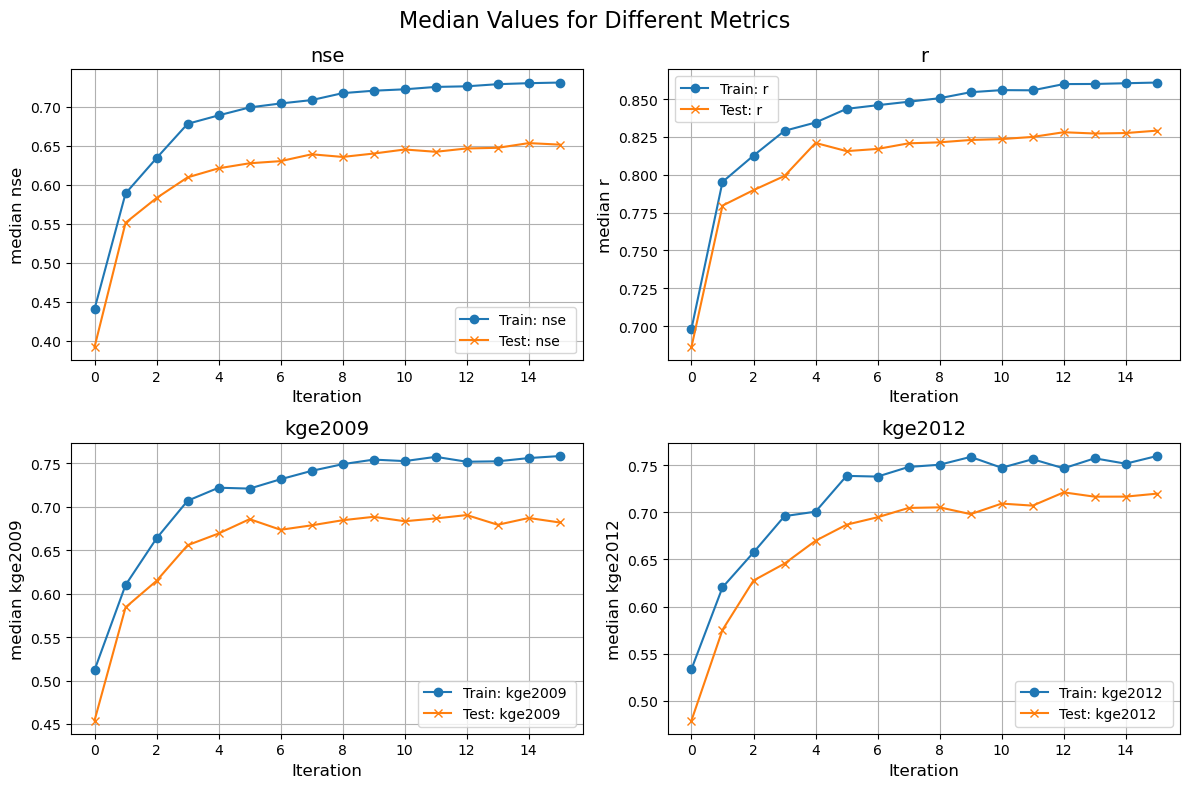

In [10]:
x_values = np.arange(iterall)

fig, axs = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle("Median Values for Different Metrics", fontsize=16)

for idx, metric in enumerate(metrics):
    row, col = divmod(idx, 2)
    axs[row, col].plot(x_values, medianvalue[idx, :, 0], label=f'Train: {metric} ', marker='o')
    axs[row, col].plot(x_values, medianvalue[idx, :, 1], label=f'Test: {metric}', marker='x')
    axs[row, col].set_title(metric, fontsize=14)
    axs[row, col].set_xlabel('Iteration', fontsize=12)
    axs[row, col].set_ylabel(f'median {metrics[idx]}', fontsize=12)
    axs[row, col].grid(True)
    axs[row, col].legend()

# Adjust layout
plt.tight_layout()  # Leave space for the title
plt.savefig(f"LSE{tarexp}_alliter_median.png", dpi=300)
plt.show()


# Plot the last iteration

In [11]:
# train/test metrics
df_train_metric = df_train_alliter.loc[df_train_alliter['iter']==iterall]
df_test_metric = df_test_alliter.loc[df_test_alliter['iter']==iterall]

In [12]:
print('Training median')
print(df_train_metric.median())

print('Testing median')
print(df_test_metric.median())

Training median
kge2009    7.552910e-01
r          8.611752e-01
alpha      8.583658e-01
beta       9.638414e-01
kge2012    7.625192e-01
rmse       1.159130e+00
me        -3.338599e-02
mae        5.088147e-01
nse        7.355829e-01
hruID      5.494490e+06
iter       1.600000e+01
dtype: float64
Testing median
kge2009    6.841236e-01
r          8.277325e-01
alpha      8.369460e-01
beta       9.255411e-01
kge2012    7.189750e-01
rmse       1.475159e+00
me        -7.931314e-02
mae        5.550305e-01
nse        6.449711e-01
hruID      5.494490e+06
iter       1.600000e+01
dtype: float64


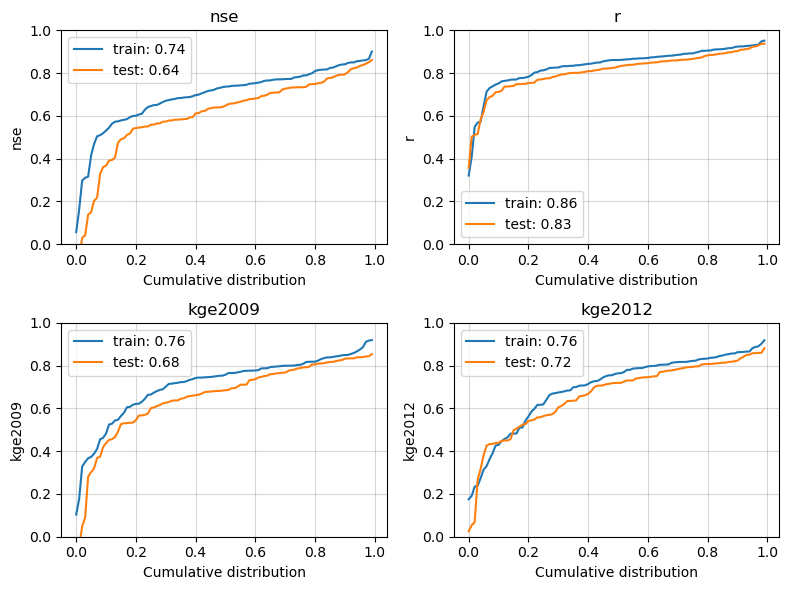

In [13]:
# Plot

metrics = ['nse', 'r', 'kge2009', 'kge2012']
fig = plt.figure(figsize=(8, 6))

for i in range(len(metrics)):
    fig.add_subplot(2,2,1+i)
    
    d1 = np.sort(df_train_metric[metrics[i]].values)
    x1 = np.arange(len(d1))/len(d1)
    plt.plot(x1, d1, label=f'train: {np.nanmedian(d1):0.2f}')
    d2 = np.sort(df_test_metric[metrics[i]].values)
    x2 = np.arange(len(d2))/len(d2)
    plt.plot(x2, d2, label=f'test: {np.nanmedian(d2):0.2f}')
    plt.legend()

    plt.ylim(0, 1)
    plt.ylabel(metrics[i])
    plt.title(metrics[i])
    plt.xlabel('Cumulative distribution')
    plt.grid('on', alpha=0.5)


plt.tight_layout()
plt.savefig(f"LSE{tarexp}_metric_CDF.png", dpi=300)
plt.show()

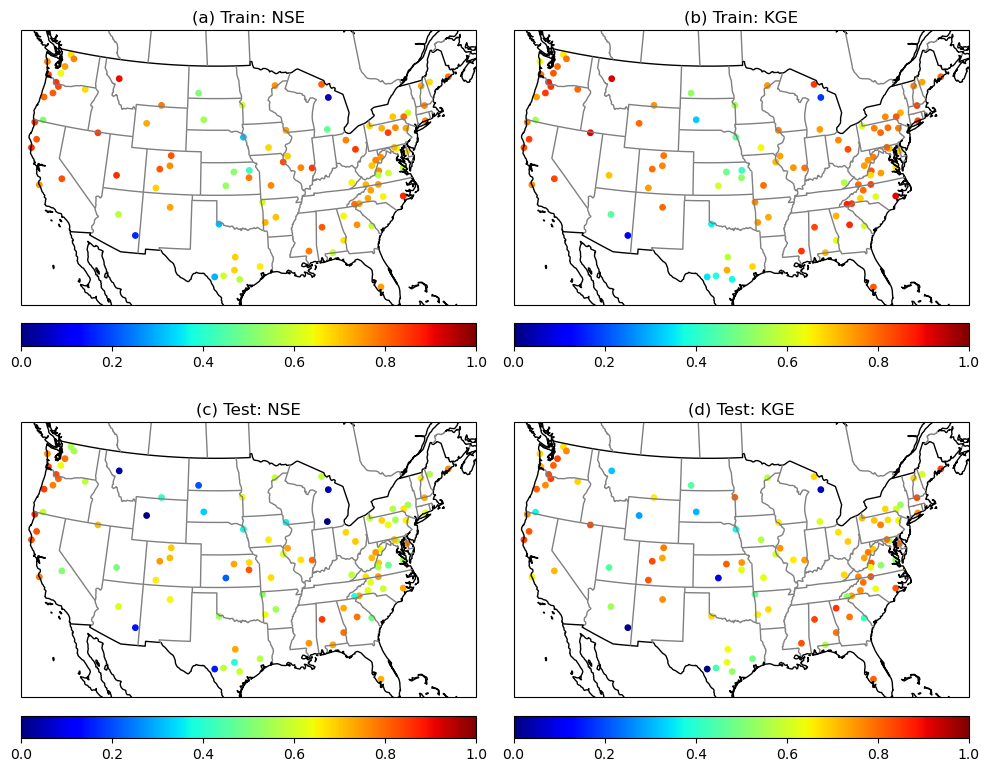

In [16]:
# spatial map: nse, kge2009


df_671 = pd.read_csv('../data/camels671_info.csv')
lat = []
lon = []
for i in camels_ids:
    index = np.squeeze(np.where(df_671['hru_id'].values==i))
    lat.append(df_671.iloc[ index ]['latoutlet'])
    lon.append(df_671.iloc[ index ]['lonoutlet'])
lat = np.array(lat)
lon = np.array(lon)


# plot

fig = plt.figure(figsize=[10, 8])

proj = ccrs.AlbersEqualArea(central_longitude=-100)
transf = ccrs.PlateCarree()

dplot = [df_train_metric['nse'].values, df_train_metric['kge2009'].values, 
         df_test_metric['nse'].values, df_test_metric['kge2009'].values, ]
title = ['(a) Train: NSE', '(b) Train: KGE', 
         '(c) Test: NSE', '(d) Test: KGE', ]

for i in range(4):
    ax = fig.add_subplot(2, 2, i+1, projection=proj)
    ax = set_background(ax)
    p = ax.scatter(lon, lat, 15, dplot[i],  vmin = 0, vmax=1, cmap='jet', transform=transf)
    ax.set_title(title[i])
    
    cax = plt.colorbar(p, ax=ax, location='bottom', shrink=1, pad=0.05)
    cax.ax.yaxis.set_ticks_position('right')
    cax.ax.yaxis.set_label_position('left')

plt.tight_layout()
plt.show()